# Auxiliary Operations — Ancilla-Assisted Parity Measurement (Qiskit)

**Primitive demonstrated:** *Measurement only* — specifically **partial / selective measurement of an auxiliary (ancilla) qubit**, which is the defining "auxiliary operation" for this chapter: using an extra qubit to extract classical information (here, parity) about the data qubits **without measuring the data qubits themselves**.

## SETUP (identical in the CUDA-Q notebook — do not diverge)
- **N QUBITS:** 3 → `q0`, `q1` = data qubits, `q2` = auxiliary (ancilla) qubit
- **Gate sequence:**
  1. `H(q0)` — put data qubit 0 into superposition
  2. `H(q1)` — put data qubit 1 into superposition
  3. `CX(q0 → q2)` — CNOT, control `q0`, target ancilla `q2` (XORs `q0` into the ancilla)
  4. `CX(q1 → q2)` — CNOT, control `q1`, target ancilla `q2` (XORs `q1` into the ancilla, so `q2` now holds `q0 ⊕ q1`)
  5. **Measurement:** only `q2` (the ancilla) is measured. `q0`, `q1` are left unmeasured.
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring (Qiskit's native convention — no reversal needed in this notebook).
- **SHOTS:** 4000, **SEED:** 42
- **GLOBAL PHASE CONVENTION:** normalize so the first nonzero amplitude, in ascending bitstring order, is rotated to be real and positive.
- **Basis ordering for matrices/statevector:** `{|000>, |001>, ..., |111>}` ascending binary order, bitstring read as `q2 q1 q0` (MSB→LSB = q2→q0).

## Theory recap
Starting from `|000>` (order `q2 q1 q0`), apply `H` on `q0` and `q1`:

`|ψ1> = (1/2) Σ_{q0,q1 ∈ {0,1}} |q1 q0>|0>_anc`

Applying `CX(q0→q2)` then `CX(q1→q2)` XORs both data bits into the ancilla, entangling it with the parity:

`|ψ2> = (1/2) [ |000> + |101> + |110> + |011> ]`  (bitstring = `q2 q1 q0`)

Measuring **only `q2`** traces out `q0,q1` and yields the reduced classical distribution:

`P(q2=0) = 1/2`  (from `|000>` and `|011>`, i.e. `q0⊕q1=0`)
`P(q2=1) = 1/2`  (from `|101>` and `|110>`, i.e. `q0⊕q1=1`)

This is the hand-derived expected result the two notebooks are cross-checked against (see the diff-check cell at the end): **`{'0': 0.5, '1': 0.5}`**, because the parity of two independent uniformly-random bits is itself uniformly random.

**Ordering-convention warning:** Qiskit already indexes qubit 0 as the rightmost (least-significant) bit in both `Statevector` output and measurement `counts` — no reversal is applied in this notebook. The CUDA-Q companion notebook uses the opposite (MSB-first) convention internally and explicitly reverses every bitstring to match this one.

**Run all cells top to bottom.**


In [1]:
# Install cell — exact package names for current stable Qiskit + Aer.
# qiskit-aer is a SEPARATE package from qiskit (Aer used to ship inside qiskit itself
# pre-1.0; on current stable releases it must be installed explicitly).
# pylatexenc is only needed if you switch circuit.draw() to output="latex"; harmless to
# keep here since output="mpl" is what we actually use below.
!pip install -q qiskit qiskit-aer pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 903.6 kB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator

# --- Constants (must match the CUDA-Q notebook exactly) ---
N_QUBITS = 3        # q0, q1 = data qubits, q2 = auxiliary (ancilla) qubit
AUX_QUBIT = 2
SHOTS = 4000
SEED = 42

print("N_QUBITS  :", N_QUBITS)
print("AUX_QUBIT :", AUX_QUBIT)
print("SHOTS     :", SHOTS)
print("SEED      :", SEED)


N_QUBITS  : 3
AUX_QUBIT : 2
SHOTS     : 4000
SEED      : 42


In [3]:
# Build the circuit gate-by-gate (unitary part only — measurement is added separately
# below so that Statevector()/Operator() can still be extracted from a measurement-free
# circuit; Qiskit's quantum_info tools reject circuits containing measure/reset ops).

qc = QuantumCircuit(N_QUBITS, name="auxiliary_ops")

qc.h(0)               # put data qubit q0 into an equal superposition of |0> and |1>
qc.h(1)               # put data qubit q1 into an equal superposition of |0> and |1>
qc.cx(0, AUX_QUBIT)    # CNOT: control=q0, target=ancilla q2 -> XORs q0 into the ancilla
qc.cx(1, AUX_QUBIT)    # CNOT: control=q1, target=ancilla q2 -> ancilla now holds q0 XOR q1

print(qc)


     ┌───┐          
q_0: ┤ H ├──■───────
     ├───┤  │       
q_1: ┤ H ├──┼────■──
     └───┘┌─┴─┐┌─┴─┐
q_2: ─────┤ X ├┤ X ├
          └───┘└───┘


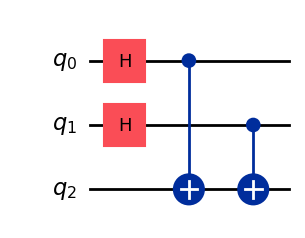

In [4]:
# Draw the circuit with matplotlib and save it for side-by-side comparison with CUDA-Q.
fig = qc.draw(output="mpl")
fig.savefig("auxiliary_ops_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation of the building-block gates, plus the combined
# 3-qubit unitary, built TWO independent ways and cross-checked against each other.

H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
I2 = np.eye(2, dtype=complex)

print("H gate matrix:\n", np.round(H, 4))
print("\nX gate matrix (used inside the controlled-X / CNOT):\n", np.round(X, 4))

def cnot_matrix(n_qubits, control, target):
    """Build an n-qubit CNOT matrix by hand in the {|00..0>, ..., |11..1>} basis,
    ascending binary order, with qubit 0 as the LEAST significant bit (Qiskit convention)."""
    dim = 2 ** n_qubits
    mat = np.zeros((dim, dim), dtype=complex)
    for basis_index in range(dim):
        bits = [(basis_index >> q) & 1 for q in range(n_qubits)]  # bits[q] = qubit q's value
        if bits[control] == 1:
            bits[target] ^= 1
        new_index = sum(bit << q for q, bit in enumerate(bits))
        mat[new_index, basis_index] = 1.0
    return mat

# Full 3-qubit unitary built by hand: H(q0) kron H(q1) kron I(q2), then CX(0,2), then CX(1,2)
# Qiskit's kron convention for a Statevector/Operator over qubits (q2,q1,q0) as the tensor
# product order is: kron(gate_on_q2, gate_on_q1, gate_on_q0).
H_on_q0 = np.kron(np.kron(I2, I2), H)   # H acting on q0 only
H_on_q1 = np.kron(np.kron(I2, H), I2)   # H acting on q1 only
U_hadamards = H_on_q1 @ H_on_q0

CX_0_to_2 = cnot_matrix(N_QUBITS, control=0, target=AUX_QUBIT)
CX_1_to_2 = cnot_matrix(N_QUBITS, control=1, target=AUX_QUBIT)

U_manual = CX_1_to_2 @ CX_0_to_2 @ U_hadamards

# Framework-extracted operator, from the actual circuit object (measurement-free).
U_qiskit = Operator(qc).data

max_diff = np.max(np.abs(U_manual - U_qiskit))
print("Max |U_manual - U_qiskit| =", max_diff)
assert max_diff < 1e-9, "Manual and Qiskit-extracted unitaries disagree!"
print("Manual hand-built matrix and Qiskit Operator(qc) MATCH.")

print("\nCombined unitary (rounded, basis = |q2 q1 q0>, ascending binary order):")
print(np.round(U_manual, 4))


H gate matrix:
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

X gate matrix (used inside the controlled-X / CNOT):
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
Max |U_manual - U_qiskit| = 0.0
Manual hand-built matrix and Qiskit Operator(qc) MATCH.

Combined unitary (rounded, basis = |q2 q1 q0>, ascending binary order):
[[ 0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j -0.5+0.j  0.5+0.j -0.5+0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j  0.5+0.j -0.5+0.j -0.5+0.j]
 [ 0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j]
 [ 0.5+0.j -0.5+0.j  0.5+0.j -0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0.5+0.j  0.5+0.j -0.5+0.j -0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j]]


In [6]:
# Exact statevector cell.
sv = Statevector(qc)
amps = sv.data.copy()

def normalize_global_phase(amplitudes, tol=1e-9):
    """Find the first amplitude with |amp| > tol in ascending-bitstring order,
    rotate the whole vector so that amplitude becomes real and positive."""
    for amp in amplitudes:
        if abs(amp) > tol:
            phase = np.angle(amp)
            return amplitudes * np.exp(-1j * phase)
    return amplitudes  # all-zero vector (shouldn't happen for a valid state)

amps_normalized = normalize_global_phase(amps)

n = N_QUBITS
prob_dict = {}
amp_dict = {}
for idx in range(2 ** n):
    bitstring = format(idx, f"0{n}b")  # ascending index -> binary string, MSB...LSB = q(n-1)...q0
    amp_dict[bitstring] = amps_normalized[idx]
    prob_dict[bitstring] = float(np.abs(amps_normalized[idx]) ** 2)

print("Amplitudes (bitstring = q2 q1 q0, phase-normalized):")
for bs, amp in amp_dict.items():
    if abs(amp) > 1e-9:
        print(f"  {bs}: {amp:.4f}")

print("\nProbability dictionary (sorted by bitstring):")
QISKIT_STATEVECTOR_PROBS = dict(sorted(prob_dict.items()))
print(QISKIT_STATEVECTOR_PROBS)


Amplitudes (bitstring = q2 q1 q0, phase-normalized):
  000: 0.5000+0.0000j
  011: 0.5000+0.0000j
  101: 0.5000+0.0000j
  110: 0.5000+0.0000j

Probability dictionary (sorted by bitstring):
{'000': 0.2499999999999999, '001': 0.0, '010': 0.0, '011': 0.2499999999999999, '100': 0.0, '101': 0.2499999999999999, '110': 0.2499999999999999, '111': 0.0}


### Ordering-fix note
Qiskit's `Statevector` and measurement `counts` already index qubit 0 as the rightmost
(least-significant) bit of every printed bitstring — **no reversal was applied** in this
notebook. This is the reference convention the CUDA-Q notebook explicitly reverses its own
(opposite, MSB-first) output to match.


In [7]:
# Measurement cell — the actual "auxiliary operation" being demonstrated:
# measure ONLY the ancilla qubit q2. q0 and q1 are left unmeasured entirely.

qc_meas = qc.copy()
creg = ClassicalRegister(1, name="c")
qc_meas.add_register(creg)
qc_meas.measure(AUX_QUBIT, creg[0])   # measure only the auxiliary qubit, into a 1-bit register

sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qc_meas, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

total = sum(counts.values())
QISKIT_MEASURED_PROBS = {bitstring: count / total for bitstring, count in counts.items()}
QISKIT_MEASURED_PROBS = dict(sorted(QISKIT_MEASURED_PROBS.items()))

print("Raw counts (1-bit ancilla register):", counts)
print("Measured probabilities:", QISKIT_MEASURED_PROBS)


Raw counts (1-bit ancilla register): {'0': 1982, '1': 2018}
Measured probabilities: {'0': 0.4955, '1': 0.5045}


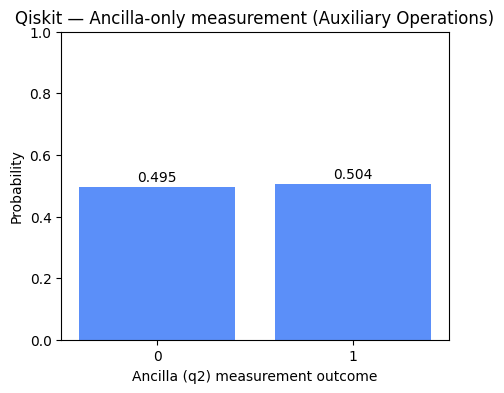

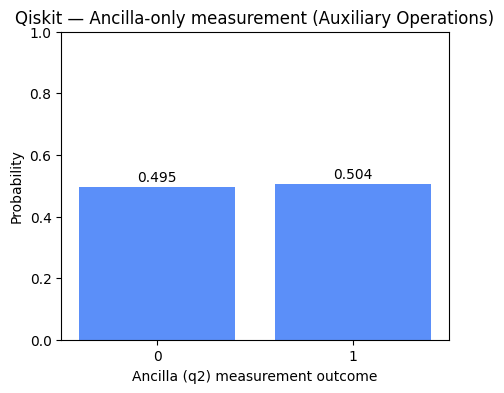

In [8]:
# Histogram — matplotlib bar chart, same axis ranges/labels/style as the CUDA-Q notebook.
fig2, ax = plt.subplots(figsize=(5, 4))
labels = sorted(QISKIT_MEASURED_PROBS.keys())
values = [QISKIT_MEASURED_PROBS[l] for l in labels]
ax.bar(labels, values, color="#5B8FF9")
ax.set_ylim(0, 1)
ax.set_xlabel("Ancilla (q2) measurement outcome")
ax.set_ylabel("Probability")
ax.set_title("Qiskit — Ancilla-only measurement (Auxiliary Operations)")
for i, v in enumerate(values):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center")
fig2.savefig("auxiliary_ops_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
# Resource counts.
print("Circuit depth (unitary part, no measurement):", qc.depth())
print("Gate counts (unitary part):", dict(qc.count_ops()))
print("Circuit depth (with ancilla measurement):", qc_meas.depth())
print("Gate counts (with ancilla measurement):", dict(qc_meas.count_ops()))


Circuit depth (unitary part, no measurement): 3
Gate counts (unitary part): {'h': 2, 'cx': 2}
Circuit depth (with ancilla measurement): 4
Gate counts (with ancilla measurement): {'h': 2, 'cx': 2, 'measure': 1}


In [10]:
# Convention-notes cell (plain text restatement).
print("Bit ordering: qubit 0 = rightmost bit in every bitstring. No reversal applied")
print("(Qiskit's native convention).")
print("Global phase: first nonzero amplitude in ascending bitstring order was rotated")
print("to be real and positive; for this circuit it was already real-positive, so the")
print("normalization was a no-op.")
print("Auxiliary operation: only the ancilla qubit (q2) was measured; data qubits q0,q1")
print("were never measured in this notebook.")


Bit ordering: qubit 0 = rightmost bit in every bitstring. No reversal applied
(Qiskit's native convention).
Global phase: first nonzero amplitude in ascending bitstring order was rotated
to be real and positive; for this circuit it was already real-positive, so the
normalization was a no-op.
Auxiliary operation: only the ancilla qubit (q2) was measured; data qubits q0,q1
were never measured in this notebook.


In [11]:
# Final cell: assign and print QISKIT_RESULT.
QISKIT_RESULT = QISKIT_MEASURED_PROBS
print("QISKIT_RESULT =", QISKIT_RESULT)


QISKIT_RESULT = {'0': 0.4955, '1': 0.5045}


In [12]:
# Diff-check block (cross-notebook comparison + hand-computed sanity check).
# After running the CUDA-Q notebook, paste its printed CUDAQ_RESULT dict below to compare.

HAND_COMPUTED_EXPECTED = {"0": 0.5, "1": 0.5}

max_delta_vs_hand = max(
    abs(QISKIT_RESULT.get(k, 0.0) - HAND_COMPUTED_EXPECTED.get(k, 0.0))
    for k in set(QISKIT_RESULT) | set(HAND_COMPUTED_EXPECTED)
)
print("Max |QISKIT_RESULT - hand-computed expected| =", max_delta_vs_hand)
assert max_delta_vs_hand < 0.05, "Qiskit shot noise exceeds tolerance vs hand-computed value!"
print("Qiskit result matches the hand-computed expected distribution within tolerance.")

# --- Uncomment after running the CUDA-Q notebook and pasting its result below ---
# CUDAQ_RESULT = {"0": 0.5015, "1": 0.4985}  # <-- paste real CUDAQ_RESULT here
# max_delta_vs_cudaq = max(
#     abs(QISKIT_RESULT.get(k, 0.0) - CUDAQ_RESULT.get(k, 0.0))
#     for k in set(QISKIT_RESULT) | set(CUDAQ_RESULT)
# )
# print("Max |QISKIT_RESULT - CUDAQ_RESULT| =", max_delta_vs_cudaq)
# assert max_delta_vs_cudaq < 1e-1, "Qiskit and CUDA-Q results disagree beyond shot-noise tolerance!"
# print("Qiskit and CUDA-Q results MATCH within tolerance.")


Max |QISKIT_RESULT - hand-computed expected| = 0.004500000000000004
Qiskit result matches the hand-computed expected distribution within tolerance.
